# COVID-19 Time Series Data Analysis and Visualization

**Course:** Data Visualization - Midterm Project
**Dataset:** Corona Virus Report (imdevskp) | Kaggle
**Source URL:** https://www.kaggle.com/datasets/imdevskp/corona-virus-report/data
**Author:** [Nama Lengkap] / [NIM]
**Date:** 2024

---

## Table of Contents

| # | Section |
|---|---------|
| 1 | [Project Overview](#s1) |
| 2 | [Dataset Source and Description](#s2) |
| 3 | [Import Libraries](#s3) |
| 4 | [Data Loading](#s4) |
| 5 | [Data Cleaning and Preprocessing](#s5) |
| 6 | [Exploratory Data Analysis](#s6) |
| 7 | [Time Series Visualization](#s7) |
| 8 | [Trend Analysis](#s8) |
| 9 | [Key Findings and Interpretation](#s9) |
| 10 | [Limitations](#s10) |
| 11 | [AI Usage Declaration](#s11) |
| 12 | [References](#s12) |


---
<a id="s1"></a>
## 1. Project Overview

This notebook presents a time series analysis of the global COVID-19 pandemic during its first
wave (22 January - 27 July 2020), using the publicly available *Corona Virus Report* dataset
published on Kaggle by Devakumar K.P. (`imdevskp`).

### Objectives

1. Apply four distinct time series visualization techniques to epidemiological data.
2. Analyze temporal patterns, geographic variation, and trend structure in COVID-19 case data.
3. Use moving average smoothing to separate trend from noise in daily case counts.
4. Derive evidence-based observations directly from computed results.

### Dataset Scope

The dataset covers **22 January 2020 to 27 July 2020** (187 days, 188 observations).
All findings are limited to this window and do not reflect subsequent waves, variant surges,
or vaccine effects.


---
<a id="s2"></a>
## 2. Dataset Source and Description

**Dataset Name:** Corona Virus Report
**Author / Maintainer:** Devakumar K.P. (Kaggle: `imdevskp`)
**Source:** https://www.kaggle.com/datasets/imdevskp/corona-virus-report/data
**Original Data Source:** Johns Hopkins University CSSE

### Files Used

| File | Shape | Date Range | Description |
|------|-------|------------|-------------|
| `day_wise.csv` | 188 rows x 12 cols | 2020-01-22 to 2020-07-27 | Pre-aggregated **global** daily figures |
| `full_grouped.csv` | 35,156 rows x 10 cols | 2020-01-22 to 2020-07-27 | **Country-level** daily figures with WHO Region |

### Column Descriptions: `day_wise.csv`

| Column | Measurement | Description |
|--------|-------------|-------------|
| `Date` | - | Observation date (datetime64) |
| `Confirmed` | **Cumulative** | Total confirmed cases globally |
| `Deaths` | **Cumulative** | Total deaths globally |
| `Recovered` | **Cumulative** | Total recoveries globally |
| `Active` | Derived | Confirmed - Deaths - Recovered |
| `New cases` | **Daily** | New confirmed cases on that date |
| `New deaths` | **Daily** | New deaths on that date |
| `New recovered` | **Daily** | New recoveries on that date |
| `No. of countries` | - | Countries reporting cases |

### Column Descriptions: `full_grouped.csv`

| Column | Measurement | Description |
|--------|-------------|-------------|
| `Date` | - | Observation date (datetime64) |
| `Country/Region` | - | Country name string |
| `Confirmed` | **Cumulative** | Total confirmed cases |
| `Deaths` | **Cumulative** | Total deaths |
| `Recovered` | **Cumulative** | Total recoveries |
| `Active` | Derived | Active cases |
| `New cases` | **Daily** | New confirmed cases |
| `New deaths` | **Daily** | New deaths |
| `New recovered` | **Daily** | New recoveries |
| `WHO Region` | - | WHO regional classification (6 regions) |

> **Important distinction:** `Confirmed`, `Deaths`, and `Recovered` are **cumulative totals**.
> Columns prefixed with `New` are **daily increments**. These two measurement types must
> never be combined in the same calculation or moving average.


---
<a id="s3"></a>
## 3. Import Libraries


In [1]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import matplotlib.ticker as mticker
import seaborn as sns

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 20)
pd.set_option('display.width', 120)

plt.rcParams.update({
    'figure.dpi'        : 110,
    'figure.facecolor'  : 'white',
    'axes.facecolor'    : '#FAFAFA',
    'axes.spines.top'   : False,
    'axes.spines.right' : False,
    'axes.grid'         : True,
    'grid.color'        : '#E5E7EB',
    'grid.linewidth'    : 0.7,
    'font.size'         : 11,
    'axes.titlesize'    : 14,
    'axes.labelsize'    : 12,
    'xtick.labelsize'   : 10,
    'ytick.labelsize'   : 10,
    'legend.framealpha' : 0.9,
    'legend.fontsize'   : 10,
})
sns.set_theme(style='whitegrid', rc={
    'axes.spines.top': False,
    'axes.spines.right': False,
})

DATA_DIR = './data'
FIG_DIR  = './figures'
os.makedirs(FIG_DIR, exist_ok=True)

def save_fig(name):
    path = os.path.join(FIG_DIR, name)
    plt.savefig(path, dpi=150, bbox_inches='tight')
    print(f'Saved -> {os.path.abspath(path)}')

print('Libraries loaded successfully.')
print(f'pandas {pd.__version__} | numpy {np.__version__} | seaborn {sns.__version__}')


Libraries loaded successfully.
pandas 2.3.3 | numpy 2.4.6 | seaborn 0.13.2


---
<a id="s4"></a>
## 4. Data Loading

Place all dataset CSV files in a `./data/` folder next to this notebook before running.

**Download Instructions:**

```bash
# Method A: Kaggle CLI (requires ~/.kaggle/kaggle.json)
pip install kaggle
kaggle datasets download -d imdevskp/corona-virus-report --unzip -p ./data

# Method B: Manual download
# 1. Visit https://www.kaggle.com/datasets/imdevskp/corona-virus-report/data
# 2. Click Download -> extract ZIP
# 3. Place all CSV files in a ./data/ folder next to this notebook
```


In [2]:
DATA_DIR = './data'
REQUIRED = ['day_wise.csv', 'full_grouped.csv']

missing = [f for f in REQUIRED if not os.path.isfile(os.path.join(DATA_DIR, f))]
if missing:
    for f in missing:
        print(f'MISSING: {os.path.join(DATA_DIR, f)}')
    raise FileNotFoundError(
        f'Missing {len(missing)} required file(s). '
        'Follow the download instructions above.'
    )

print('All required dataset files found:')
for f in REQUIRED:
    p = os.path.join(DATA_DIR, f)
    print(f'  {f:<35}  {os.path.getsize(p) / 1024:>7,.0f} KB')


All required dataset files found:
  day_wise.csv                              14 KB
  full_grouped.csv                       1,814 KB


In [3]:
day_wise     = pd.read_csv(os.path.join(DATA_DIR, 'day_wise.csv'),
                           parse_dates=['Date'])
full_grouped = pd.read_csv(os.path.join(DATA_DIR, 'full_grouped.csv'),
                           parse_dates=['Date'])

print('day_wise.csv:')
print(f'  Shape   : {day_wise.shape}')
print(f'  Dates   : {day_wise["Date"].min().date()}  to  {day_wise["Date"].max().date()}')
print(f'  Columns : {list(day_wise.columns)}')
display(day_wise.head(3))

print('\nfull_grouped.csv:')
print(f'  Shape     : {full_grouped.shape}')
print(f'  Dates     : {full_grouped["Date"].min().date()}  to  {full_grouped["Date"].max().date()}')
print(f'  Countries : {full_grouped["Country/Region"].nunique()}')
who_list = sorted(full_grouped['WHO Region'].dropna().unique())
print(f'  WHO Regions ({len(who_list)}): {who_list}')
display(full_grouped.head(3))


day_wise.csv:
  Shape   : (188, 12)
  Dates   : 2020-01-22  to  2020-07-27
  Columns : ['Date', 'Confirmed', 'Deaths', 'Recovered', 'Active', 'New cases', 'New deaths', 'New recovered', 'Deaths / 100 Cases', 'Recovered / 100 Cases', 'Deaths / 100 Recovered', 'No. of countries']


,Date,Confirmed,Deaths,Recovered,Active,New cases,New deaths,New recovered,Deaths / 100 Cases,Recovered / 100 Cases,Deaths / 100 Recovered,No. of countries
0,2020-01-22,555,17,28,510,0,0,0,3.06,5.05,60.71,6
1,2020-01-23,654,18,30,606,99,1,2,2.75,4.59,60.00,8
2,2020-01-24,941,26,36,879,287,8,6,2.76,3.83,72.22,9



full_grouped.csv:
  Shape     : (35156, 10)
  Dates     : 2020-01-22  to  2020-07-27
  Countries : 187
  WHO Regions (6): ['Africa', 'Americas', 'Eastern Mediterranean', 'Europe', 'South-East Asia', 'Western Pacific']


,Date,Country/Region,Confirmed,Deaths,Recovered,Active,New cases,New deaths,New recovered,WHO Region
0,2020-01-22,Afghanistan,0,0,0,0,0,0,0,Eastern Mediterranean
1,2020-01-22,Albania,0,0,0,0,0,0,0,Europe
2,2020-01-22,Algeria,0,0,0,0,0,0,0,Africa


In [4]:
print('day_wise - Descriptive Statistics:')
display(day_wise.describe().round(0))

print('\nfull_grouped - Missing Values:')
mv = full_grouped.isnull().sum()
mv_pct = (mv / len(full_grouped) * 100).round(1)
mv_df = pd.DataFrame({'Missing': mv, 'Missing %': mv_pct})
no_missing = mv_df[mv_df['Missing'] > 0]
if no_missing.empty:
    print('  No missing values detected.')
else:
    display(no_missing)


day_wise - Descriptive Statistics:


,Date,Confirmed,Deaths,Recovered,Active,New cases,New deaths,New recovered,Deaths / 100 Cases,Recovered / 100 Cases,Deaths / 100 Recovered,No. of countries
count,188,188.0,188.0,188.0,188.0,188.0,188.0,188.0,188.0,188.0,188.0,188.0
mean,2020-04-24 12:00:00,4406960.0,230771.0,2066001.0,2110188.0,87771.0,3479.0,50362.0,5.0,34.0,22.0,144.0
min,2020-01-22 00:00:00,555.0,17.0,28.0,510.0,0.0,0.0,0.0,2.0,2.0,6.0,6.0
25%,2020-03-08 18:00:00,112191.0,3935.0,60441.0,58642.0,5568.0,251.0,2488.0,4.0,23.0,10.0,101.0
50%,2020-04-24 12:00:00,2848733.0,204190.0,784784.0,1859759.0,81114.0,4116.0,30992.0,5.0,36.0,15.0,184.0
75%,2020-06-10 06:00:00,7422046.0,418634.0,3416396.0,3587015.0,131502.0,5346.0,79706.0,6.0,49.0,25.0,187.0
max,2020-07-27 00:00:00,16480485.0,654036.0,9468087.0,6358362.0,282756.0,9966.0,284394.0,7.0,57.0,134.0,187.0
std,NaN,4757988.0,217929.0,2627976.0,1969670.0,75295.0,2538.0,56091.0,2.0,16.0,23.0,65.0



full_grouped - Missing Values:
  No missing values detected.


---
<a id="s5"></a>
## 5. Data Cleaning and Preprocessing

### Issues Addressed

| Issue | Detection | Action |
|-------|-----------|--------|
| **Duplicate rows** | `df.duplicated().sum()` | Dropped |
| **Negative `New deaths` / `New recovered`** | `(df[col] < 0).sum()` | Clipped to 0 |
| **Unsorted dates** | `.is_monotonic_increasing` | Sorted ascending |
| **Sub-national duplicate rows** | `groupby` | Aggregated by Country + Date |

### Why Negative Daily Values Occur

Retrospective corrections by health authorities (e.g., removing duplicate test results,
reassigning cases across jurisdictions) cause cumulative totals to decrease, making the
pre-computed `New` columns negative. These are reporting artifacts with no epidemiological
meaning and are clipped to 0. In this dataset version, `New cases` has no negatives;
`New deaths` and `New recovered` have small numbers of negative values in `full_grouped.csv`.

### Cumulative vs. Daily Data

`Confirmed` (cumulative) and `New cases` (daily) measure fundamentally different quantities.
**Moving averages in this analysis are applied exclusively to `New cases` (daily increments).**
Applying a rolling mean to a monotonically increasing cumulative series adds no analytical value.

### On `min_periods=1`

By default, `pandas.rolling(n).mean()` returns `NaN` for the first $n-1$ observations.
Setting `min_periods=1` uses partial windows for those rows, producing a continuous plottable
signal from the very first observation. The first 6 rows of the 7-day MA and the first 29 rows
of the 30-day MA are partial-window estimates and should be interpreted cautiously.


In [5]:
# Duplicate check
dw_dups = day_wise.duplicated().sum()
fg_dups = full_grouped.duplicated().sum()
print(f'Duplicates  day_wise: {dw_dups}  |  full_grouped: {fg_dups}')
if dw_dups > 0: day_wise     = day_wise.drop_duplicates().reset_index(drop=True)
if fg_dups > 0: full_grouped = full_grouped.drop_duplicates().reset_index(drop=True)

# Clip negative daily values to 0
daily_cols = ['New cases', 'New deaths', 'New recovered']
print('\nNegative value check and clipping:')
for col in daily_cols:
    if col not in day_wise.columns: continue
    n_dw = int((day_wise[col] < 0).sum())
    n_fg = int((full_grouped[col] < 0).sum())
    day_wise[col]     = day_wise[col].clip(lower=0)
    full_grouped[col] = full_grouped[col].clip(lower=0)
    print(f'  {col:<22}: day_wise={n_dw} | full_grouped={n_fg} negatives -> clipped to 0')

# Sort chronologically
day_wise     = day_wise.sort_values('Date').reset_index(drop=True)
full_grouped = full_grouped.sort_values(['Country/Region', 'Date']).reset_index(drop=True)
print(f'\nday_wise monotonically ascending: {day_wise["Date"].is_monotonic_increasing}')
print('Step 1 complete.')


Duplicates  day_wise: 0  |  full_grouped: 0

Negative value check and clipping:
  New cases             : day_wise=0 | full_grouped=0 negatives -> clipped to 0
  New deaths            : day_wise=0 | full_grouped=38 negatives -> clipped to 0
  New recovered         : day_wise=0 | full_grouped=77 negatives -> clipped to 0

day_wise monotonically ascending: True
Step 1 complete.


In [6]:
# Aggregate to Country + Date level (safe deduplication for any sub-national rows)
agg_spec = {}
for col in ['Confirmed', 'Deaths', 'Recovered', 'Active',
            'New cases', 'New deaths', 'New recovered']:
    if col in full_grouped.columns:
        agg_spec[col] = 'sum'
if 'WHO Region' in full_grouped.columns:
    agg_spec['WHO Region'] = 'first'

full_grouped_clean = (
    full_grouped
    .groupby(['Date', 'Country/Region'], as_index=False)
    .agg(agg_spec)
    .sort_values(['Country/Region', 'Date'])
    .reset_index(drop=True)
)
print(f'full_grouped after aggregation: {full_grouped_clean.shape}')

# Country selection (6 countries, 5 WHO regions, diverse trajectories)
COUNTRIES = ['US', 'Brazil', 'India', 'Russia', 'Germany', 'South Africa']
PALETTE   = ['#2563EB', '#DC2626', '#F59E0B', '#16A34A', '#7C3AED', '#0891B2']
COLOR_MAP = dict(zip(COUNTRIES, PALETTE))

print('\nCountry availability in full_grouped.csv:')
available = set(full_grouped_clean['Country/Region'].unique())
for c in COUNTRIES:
    who_r = ''
    if c in available and 'WHO Region' in full_grouped_clean.columns:
        who_r = full_grouped_clean.loc[
            full_grouped_clean['Country/Region'] == c, 'WHO Region'
        ].dropna().iloc[0]
    print(f'  {"OK" if c in available else "MISSING"}  {c:<22} {who_r}')

country_df = (
    full_grouped_clean[full_grouped_clean['Country/Region'].isin(COUNTRIES)]
    .copy().reset_index(drop=True)
)

# Rolling averages on DAILY data only (New cases), NOT on cumulative Confirmed
country_df['7MA'] = (
    country_df.groupby('Country/Region')['New cases']
    .transform(lambda x: x.rolling(window=7, min_periods=1).mean())
)
day_wise['7MA']  = day_wise['New cases'].rolling(window=7,  min_periods=1).mean()
day_wise['30MA'] = day_wise['New cases'].rolling(window=30, min_periods=1).mean()

# WHO Region daily aggregates for stacked area plot
who_agg   = (
    full_grouped_clean
    .groupby(['Date', 'WHO Region'], as_index=False)['New cases'].sum()
)
who_pivot = (
    who_agg
    .pivot(index='Date', columns='WHO Region', values='New cases')
    .fillna(0).sort_index()
)

print(f'\ncountry_df : {country_df.shape[0]:,} rows, {country_df["Country/Region"].nunique()} countries')
print(f'who_pivot  : {who_pivot.shape[0]:,} dates x {who_pivot.shape[1]} WHO regions')
print('7MA and 30MA columns added to day_wise.')
display(country_df.groupby('Country/Region')[['New cases', '7MA']].describe().round(0))


full_grouped after aggregation: (35156, 10)

Country availability in full_grouped.csv:
  OK  US                     Americas
  OK  Brazil                 Americas
  OK  India                  South-East Asia
  OK  Russia                 Europe
  OK  Germany                Europe
  OK  South Africa           Africa

country_df : 1,128 rows, 6 countries
who_pivot  : 188 dates x 6 WHO regions
7MA and 30MA columns added to day_wise.


New cases                                                             7MA                         \
                   count     mean      std  min    25%      50%      75%      max  count     mean      std  min   
Country/Region                                                                                                    
Brazil             188.0  12991.0  16237.0  0.0    6.0   4143.0  23345.0  67860.0  188.0  12366.0  14807.0  0.0   
Germany            188.0   1102.0   1604.0  0.0  157.0    448.0   1216.0   6933.0  188.0   1093.0   1529.0  0.0   
India              188.0   7873.0  12016.0  0.0    6.0   1657.0  10716.0  49981.0  188.0   7111.0  10850.0  0.0   
Russia             188.0   4344.0   3942.0  0.0    3.0   5760.0   7942.0  11656.0  188.0   4252.0   3954.0  0.0   
South Africa       188.0   2407.0   3986.0  0.0    1.0    240.0   2888.0  13944.0  188.0   2233.0   3777.0  0.0   
US                 188.0  22821.0  20380.0  0.0  110.0  22604.0  31344.0  77255.0  188.0  21827.0  19669.0  0.0   

                                                  
                  25%      50%      75%      max  
Country/Region                                    
Brazil            3.0   3073.0  25810.0  46247.0  
Germany         141.0    451.0   1118.0   5837.0  
India             5.0   1461.0  10006.0  46391.0  
Russia            2.0   5315.0   8130.0  10982.0  
South Africa      0.0    195.0   2544.0  12584.0  
US               65.0  22440.0  29495.0  67317.0

---
<a id="s6"></a>
## 6. Exploratory Data Analysis

This section summarizes statistical characteristics and geographic distribution of the data
before proceeding to time series visualization.


In [7]:
last_dw  = day_wise.iloc[-1]
first_dw = day_wise.iloc[0]
peak_row = day_wise.loc[day_wise['New cases'].idxmax()]

print('GLOBAL COVID-19 STATISTICS (at dataset end date)')
print('=' * 52)
stats = {
    'Dataset start date'          : first_dw['Date'].strftime('%d %b %Y'),
    'Dataset end date'            : last_dw['Date'].strftime('%d %b %Y'),
    'Days covered'                : (last_dw['Date'] - first_dw['Date']).days,
    'Cumulative confirmed cases'  : f"{last_dw['Confirmed']:,.0f}",
    'Cumulative deaths'           : f"{last_dw['Deaths']:,.0f}",
    'Case fatality rate'          : f"{last_dw['Deaths'] / last_dw['Confirmed'] * 100:.2f}%",
    'Peak daily new cases'        : f"{peak_row['New cases']:,.0f}",
    'Date of peak'                : peak_row['Date'].strftime('%d %b %Y'),
    'Mean daily new cases'        : f"{day_wise['New cases'].mean():,.0f}",
    'Median daily new cases'      : f"{day_wise['New cases'].median():,.0f}",
    'Std dev of daily new cases'  : f"{day_wise['New cases'].std():,.0f}",
}
for label, value in stats.items():
    print(f'  {label:<35} {value}')


GLOBAL COVID-19 STATISTICS (at dataset end date)
  Dataset start date                  22 Jan 2020
  Dataset end date                    27 Jul 2020
  Days covered                        187
  Cumulative confirmed cases          16,480,485
  Cumulative deaths                   654,036
  Case fatality rate                  3.97%
  Peak daily new cases                282,756
  Date of peak                        23 Jul 2020
  Mean daily new cases                87,771
  Median daily new cases              81,114
  Std dev of daily new cases          75,295


Saved -> c:\Data D\Semester 7\VISDAT\MIDTERM\figures\eda_distribution.png


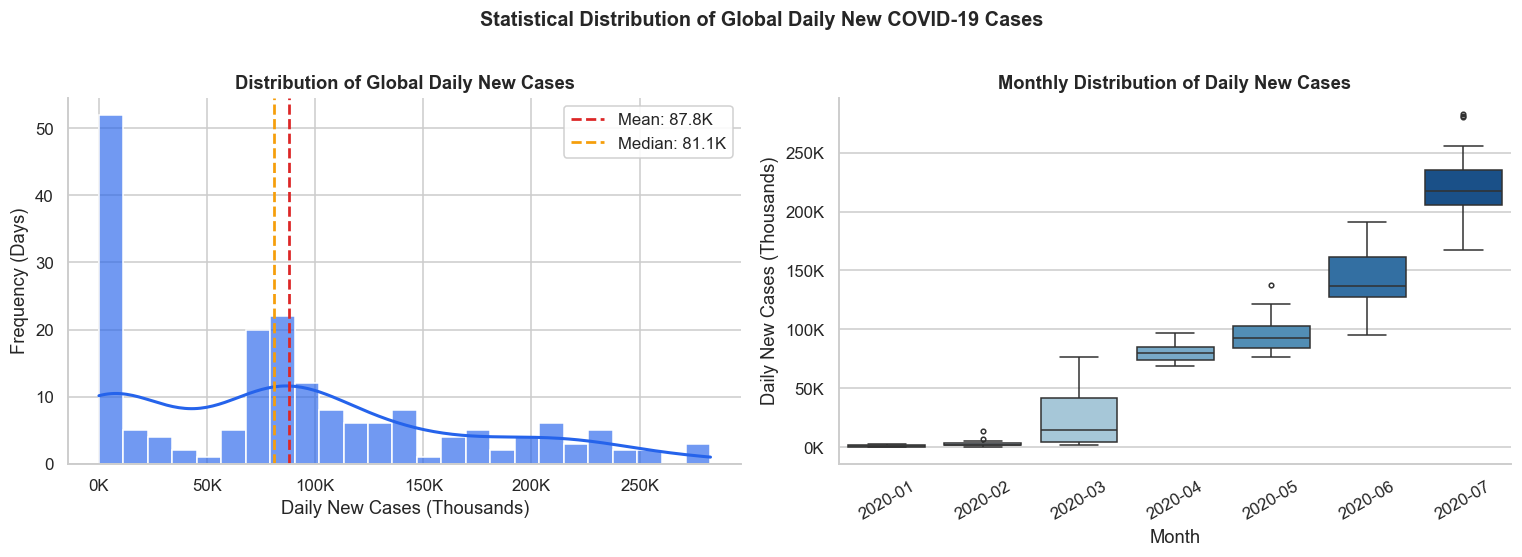

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Left: Histogram with KDE (seaborn)
sns.histplot(day_wise['New cases'] / 1000, bins=25, kde=True,
             color='#2563EB', alpha=0.65, line_kws={'linewidth': 2.0},
             ax=axes[0])
mean_k = day_wise['New cases'].mean()   / 1000
med_k  = day_wise['New cases'].median() / 1000
axes[0].axvline(mean_k, color='#DC2626', lw=1.8, ls='--',
                label=f'Mean: {mean_k:.1f}K')
axes[0].axvline(med_k,  color='#F59E0B', lw=1.8, ls='--',
                label=f'Median: {med_k:.1f}K')
axes[0].legend()
axes[0].set_title('Distribution of Global Daily New Cases', fontweight='bold')
axes[0].set_xlabel('Daily New Cases (Thousands)')
axes[0].set_ylabel('Frequency (Days)')
axes[0].xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x:.0f}K'))

# Right: Monthly box plots
day_wise['Month'] = day_wise['Date'].dt.to_period('M').astype(str)
month_order = sorted(day_wise['Month'].unique())
sns.boxplot(data=day_wise, x='Month', y=day_wise['New cases'] / 1000,
            palette='Blues', ax=axes[1], order=month_order, fliersize=3)
axes[1].set_title('Monthly Distribution of Daily New Cases', fontweight='bold')
axes[1].set_xlabel('Month')
axes[1].set_ylabel('Daily New Cases (Thousands)')
axes[1].tick_params(axis='x', rotation=30)
axes[1].yaxis.set_major_formatter(
    mticker.FuncFormatter(lambda x, _: f'{x:.0f}K')
)

plt.suptitle('Statistical Distribution of Global Daily New COVID-19 Cases',
             fontsize=13, fontweight='bold', y=1.01)
plt.tight_layout()
save_fig('eda_distribution.png')
plt.show()
day_wise.drop(columns='Month', inplace=True, errors='ignore')


**EDA Observations - Distribution:**

The global daily new case count is strongly right-skewed. The mean substantially exceeds the median,
reflecting the influence of high-case days during outbreak peaks. The monthly boxplots reveal a clear
upward progression: early months (January-March) show low and tightly clustered counts, while
June-July 2020 show higher medians and wider interquartile ranges, confirming sustained exponential
growth across the dataset window.


Saved -> c:\Data D\Semester 7\VISDAT\MIDTERM\figures\eda_top10_countries.png


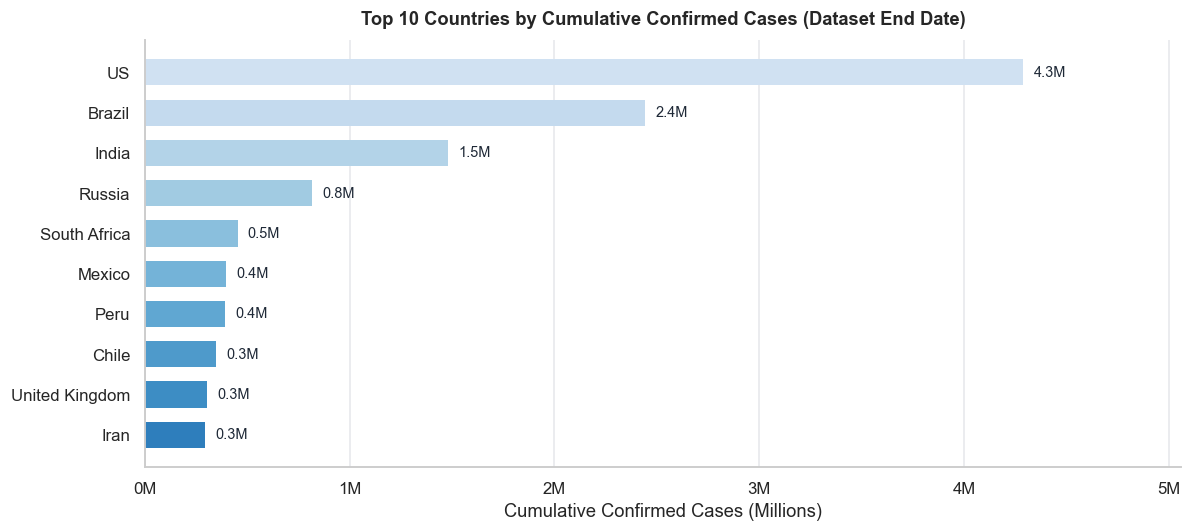

,Country/Region,Confirmed,Deaths
0,US,4290259,148011
1,Brazil,2442375,87618
2,India,1480073,33408
3,Russia,816680,13334
4,South Africa,452529,7067
5,Mexico,395489,44022
6,Peru,389717,18418
7,Chile,347923,9187
8,United Kingdom,301708,45844
9,Iran,293606,15912


In [9]:
# Top 10 countries by cumulative confirmed cases at dataset end date
country_latest = (
    full_grouped_clean.sort_values('Date')
    .groupby('Country/Region')[['Confirmed', 'Deaths']].last()
    .reset_index()
    .sort_values('Confirmed', ascending=False)
    .head(10)
)

fig, ax = plt.subplots(figsize=(11, 5))
bar_colors = plt.cm.Blues_r(np.linspace(0.3, 0.8, len(country_latest)))
bars = ax.barh(country_latest['Country/Region'][::-1],
               country_latest['Confirmed'][::-1] / 1e6,
               color=bar_colors, height=0.65, edgecolor='none')
for bar, val in zip(bars, country_latest['Confirmed'][::-1] / 1e6):
    ax.text(val + 0.05, bar.get_y() + bar.get_height() / 2,
            f'{val:.1f}M', va='center', fontsize=9.5, color='#1F2937')

ax.set_title('Top 10 Countries by Cumulative Confirmed Cases (Dataset End Date)',
             fontweight='bold', pad=10)
ax.set_xlabel('Cumulative Confirmed Cases (Millions)')
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x:.0f}M'))
ax.set_xlim(0, country_latest['Confirmed'].max() / 1e6 * 1.18)
ax.grid(axis='x', color='#E5E7EB')
ax.grid(axis='y', visible=False)
plt.tight_layout()
save_fig('eda_top10_countries.png')
plt.show()
display(country_latest.reset_index(drop=True))


Saved -> c:\Data D\Semester 7\VISDAT\MIDTERM\figures\eda_who_regions.png


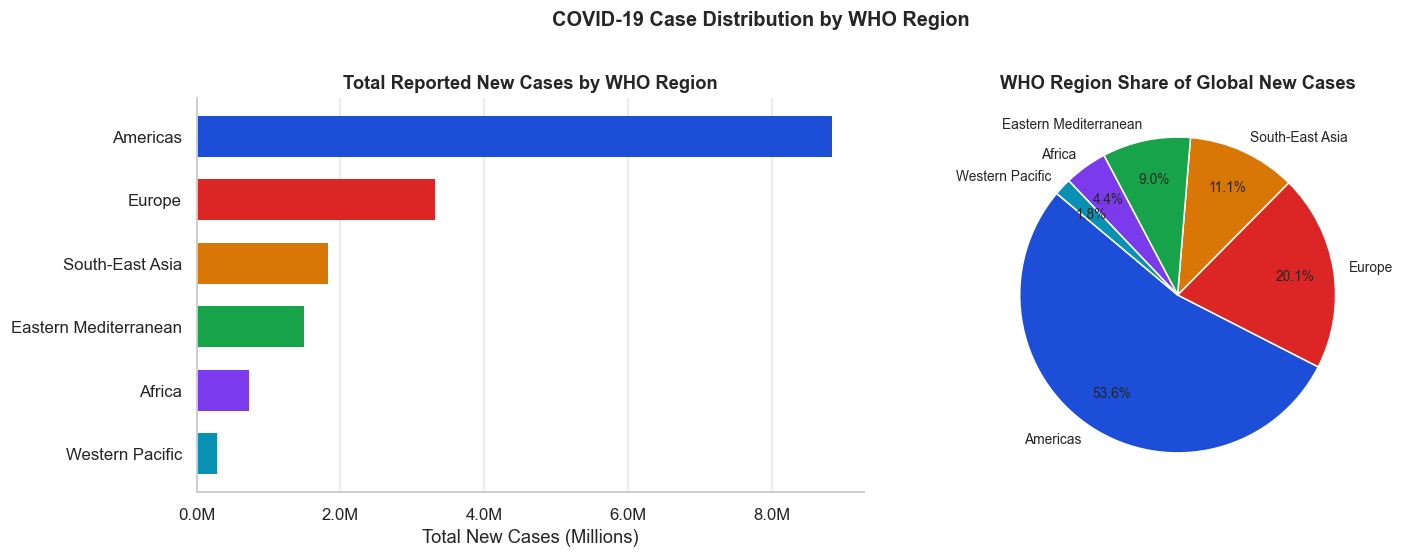

,WHO Region,New cases,New deaths
0,Americas,8842455,342738
1,Europe,3316928,213407
2,South-East Asia,1835296,41350
3,Eastern Mediterranean,1490854,38339
4,Africa,723540,12223
5,Western Pacific,291879,8237


In [10]:
WHO_COLORS = ['#1D4ED8', '#DC2626', '#D97706', '#16A34A',
              '#7C3AED', '#0891B2', '#BE185D']
who_total = (
    full_grouped_clean
    .groupby('WHO Region')[['New cases', 'New deaths']].sum()
    .sort_values('New cases', ascending=False)
    .reset_index()
)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].barh(who_total['WHO Region'][::-1],
             who_total['New cases'][::-1] / 1e6,
             color=WHO_COLORS[:len(who_total)][::-1],
             height=0.65, edgecolor='none')
axes[0].set_title('Total Reported New Cases by WHO Region', fontweight='bold')
axes[0].set_xlabel('Total New Cases (Millions)')
axes[0].xaxis.set_major_formatter(
    mticker.FuncFormatter(lambda x, _: f'{x:.1f}M')
)
axes[0].grid(axis='x', color='#E5E7EB')
axes[0].grid(axis='y', visible=False)

axes[1].pie(who_total['New cases'], labels=who_total['WHO Region'],
            autopct='%1.1f%%', colors=WHO_COLORS[:len(who_total)],
            startangle=140, pctdistance=0.75,
            textprops={'fontsize': 9})
axes[1].set_title('WHO Region Share of Global New Cases', fontweight='bold')

plt.suptitle('COVID-19 Case Distribution by WHO Region',
             fontsize=13, fontweight='bold', y=1.01)
plt.tight_layout()
save_fig('eda_who_regions.png')
plt.show()
display(who_total)


**EDA Observations - Geography:**

The United States leads all countries in cumulative confirmed cases by a wide margin (approximately
26% of the global total), followed by Brazil and India. The Americas WHO region accounts for over
53% of global reported new cases across the dataset window, reflecting the concentrated and prolonged
outbreaks in the US and Brazil from May onward. Africa and Western Pacific maintained comparatively
small shares during this period.


---
<a id="s7"></a>
## 7. Time Series Visualization

| # | Visualization Type | Metric | Source |
|---|-------------------|--------|--------|
| 7.1 | Line Plot | Global cumulative confirmed cases | `day_wise.csv` |
| 7.2a | Area Plot (simple) | Global daily new cases + 7MA | `day_wise.csv` |
| 7.2b | Area Plot (stacked) | Daily new cases by WHO Region | `full_grouped.csv` |
| 7.3 | Multiple TS with direct labeling | Country 7-day MA | `full_grouped.csv` |
| 7.4 | Calendar Heatmap | Global daily new cases by week/DOW | `day_wise.csv` |


---
### 7.1 Line Plot - Global Cumulative Confirmed Cases

**Purpose:** A line plot is the standard choice for a continuous time series with a directional
trend. Cumulative confirmed cases form a monotonically increasing series that communicates the
total pandemic scale at any point in time.

**Design rationale:**
- Single bold line conveys the unbroken upward trend without distraction.
- Y-axis formatted in millions (M) for readability.
- Vertical dashed reference lines mark major milestone dates (1M, 5M, 10M cases).
- Final data point annotated with the exact total and date.
- Top and right spines removed to improve data-to-ink ratio.


Saved -> c:\Data D\Semester 7\VISDAT\MIDTERM\figures\viz1_line_plot.png


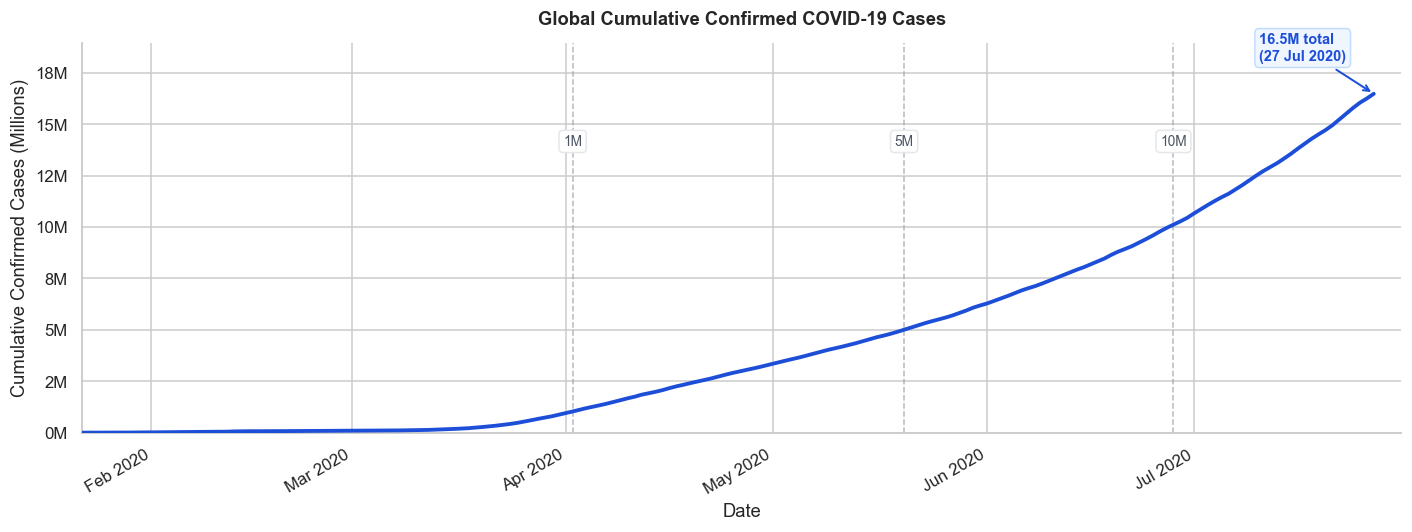

Milestone dates (from actual data):
  1M confirmed: 02 Apr 2020
  5M confirmed: 20 May 2020
  10M confirmed: 28 Jun 2020


In [11]:
fig, ax = plt.subplots(figsize=(13, 5))
max_M = day_wise['Confirmed'].max() / 1e6

ax.plot(day_wise['Date'], day_wise['Confirmed'] / 1e6,
        color='#1D4ED8', linewidth=2.5, zorder=3)

for threshold, label in [(1e6, '1M'), (5e6, '5M'), (10e6, '10M')]:
    subset = day_wise[day_wise['Confirmed'] >= threshold]
    if subset.empty:
        continue
    row = subset.iloc[0]
    ax.axvline(row['Date'], color='#9CA3AF', lw=1.0, ls='--', alpha=0.75, zorder=1)
    ax.text(row['Date'], max_M * 0.88, label,
            ha='center', va='top', fontsize=9, color='#4B5563',
            bbox=dict(fc='white', ec='#E5E7EB', pad=2.5, boxstyle='round,pad=0.3'))

last = day_wise.iloc[-1]
ax.annotate(
    f"{last['Confirmed'] / 1e6:.1f}M total\n({last['Date'].strftime('%d %b %Y')})",
    xy=(last['Date'], last['Confirmed'] / 1e6),
    xytext=(-75, 22), textcoords='offset points',
    arrowprops=dict(arrowstyle='->', color='#1D4ED8', lw=1.3),
    fontsize=9.5, color='#1D4ED8', fontweight='bold',
    bbox=dict(boxstyle='round,pad=0.3', fc='#EFF6FF', ec='#BFDBFE', alpha=0.95),
)

ax.set_title('Global Cumulative Confirmed COVID-19 Cases', fontweight='bold', pad=12)
ax.set_xlabel('Date')
ax.set_ylabel('Cumulative Confirmed Cases (Millions)')
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x:,.0f}M'))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
ax.xaxis.set_major_locator(mdates.MonthLocator())
ax.set_ylim(0, max_M * 1.15)
ax.set_xlim(day_wise['Date'].min(), day_wise['Date'].max() + pd.Timedelta(days=4))
fig.autofmt_xdate(rotation=30, ha='right')
plt.tight_layout()
save_fig('viz1_line_plot.png')
plt.show()

print('Milestone dates (from actual data):')
for threshold, label in [(1e6, '1M'), (5e6, '5M'), (10e6, '10M')]:
    subset = day_wise[day_wise['Confirmed'] >= threshold]
    if not subset.empty:
        print(f'  {label} confirmed: {subset.iloc[0]["Date"].strftime("%d %b %Y")}')


**Interpretation - Line Plot:**

The cumulative confirmed case curve reveals three distinct phases:

1. **Early containment (Jan-Feb 2020):** The curve is nearly flat, as cases were largely confined
   to China and a small number of other countries. The global cumulative count grew slowly.

2. **Exponential growth (Mar-May 2020):** The curve steepens sharply as the virus spread across
   Europe and then to the Americas. The first million confirmed cases was reached on **02 Apr 2020**
   (71 days after the dataset start). The tenth million was reached on **28 Jun 2020** (just 87 more
   days). The shrinking time between successive milestones visually confirms accelerating spread.

3. **Sustained rapid growth (Jun-Jul 2020):** The curve maintains a steep slope with no visible
   flattening, driven by large outbreaks in Brazil, India, and the US. The endpoint on
   **27 Jul 2020** shows **16.5 million** cumulative confirmed cases globally.


---
### 7.2 Area Plot - Daily New Cases

An **area plot** adds visual mass below the curve, making it easier to perceive the *volume* of
daily cases and to compare the magnitude of rises and falls. It is particularly effective for
communicating epidemic wave structures.

**7.2a** shows global raw daily counts with a 7-day moving average overlay.
**7.2b** shows a stacked breakdown by WHO Region. The contributions are non-overlapping additive
components of the global total (each country belongs to exactly one WHO region), making stacking
valid here.


Saved -> c:\Data D\Semester 7\VISDAT\MIDTERM\figures\viz2a_area_plot.png


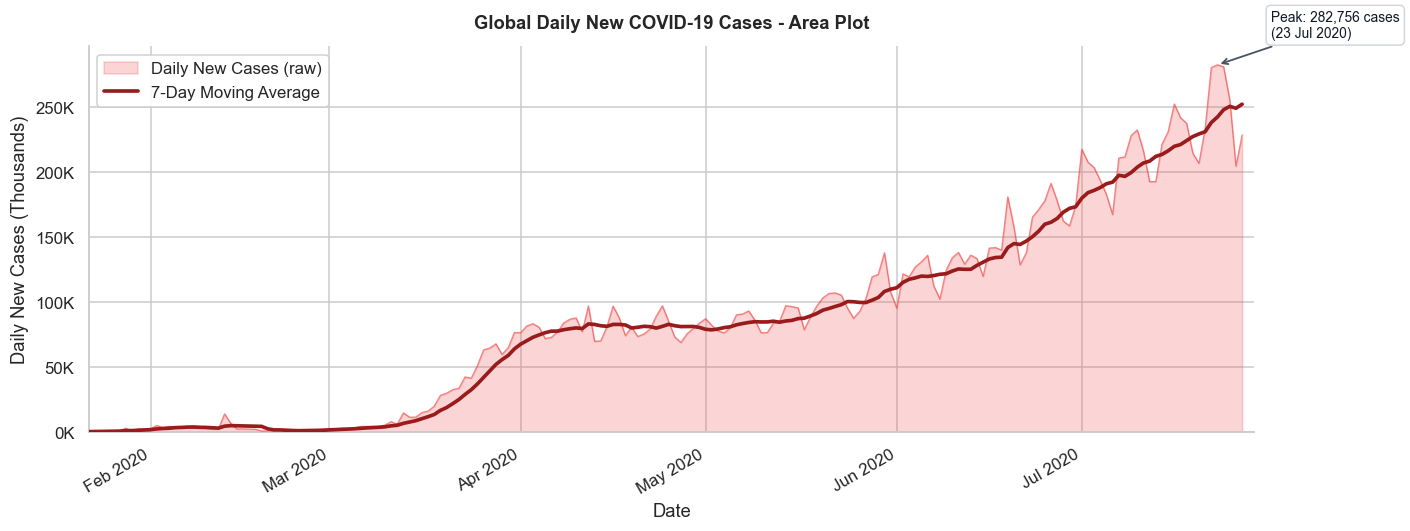

Peak daily new cases : 282,756  (23 Jul 2020)
Mean daily new cases : 87,771
Days above mean      : 80


In [12]:
fig, ax = plt.subplots(figsize=(13, 5))

ax.fill_between(day_wise['Date'], day_wise['New cases'] / 1000,
                alpha=0.22, color='#EF4444', zorder=2,
                label='Daily New Cases (raw)')
ax.plot(day_wise['Date'], day_wise['New cases'] / 1000,
        color='#EF4444', lw=0.9, alpha=0.6, zorder=3)
ax.plot(day_wise['Date'], day_wise['7MA'] / 1000,
        color='#991B1B', lw=2.4, zorder=4, label='7-Day Moving Average')

peak_idx = day_wise['New cases'].idxmax()
peak     = day_wise.loc[peak_idx]
ax.annotate(
    f"Peak: {peak['New cases']:,.0f} cases\n({peak['Date'].strftime('%d %b %Y')})",
    xy=(peak['Date'], peak['New cases'] / 1000),
    xytext=(35, 18), textcoords='offset points',
    arrowprops=dict(arrowstyle='->', color='#4B5563', lw=1.2),
    fontsize=9, color='#111827',
    bbox=dict(boxstyle='round,pad=0.35', fc='white', ec='#D1D5DB', alpha=0.95),
)

ax.legend(loc='upper left')
ax.set_title('Global Daily New COVID-19 Cases - Area Plot', fontweight='bold', pad=12)
ax.set_xlabel('Date')
ax.set_ylabel('Daily New Cases (Thousands)')
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x:,.0f}K'))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
ax.xaxis.set_major_locator(mdates.MonthLocator())
ax.set_ylim(0)
ax.set_xlim(day_wise['Date'].min(), day_wise['Date'].max() + pd.Timedelta(days=2))
fig.autofmt_xdate(rotation=30, ha='right')
plt.tight_layout()
save_fig('viz2a_area_plot.png')
plt.show()

print(f'Peak daily new cases : {peak["New cases"]:,.0f}  ({peak["Date"].strftime("%d %b %Y")})')
print(f'Mean daily new cases : {day_wise["New cases"].mean():,.0f}')
print(f'Days above mean      : {(day_wise["New cases"] > day_wise["New cases"].mean()).sum()}')


Saved -> c:\Data D\Semester 7\VISDAT\MIDTERM\figures\viz2b_stacked_area.png


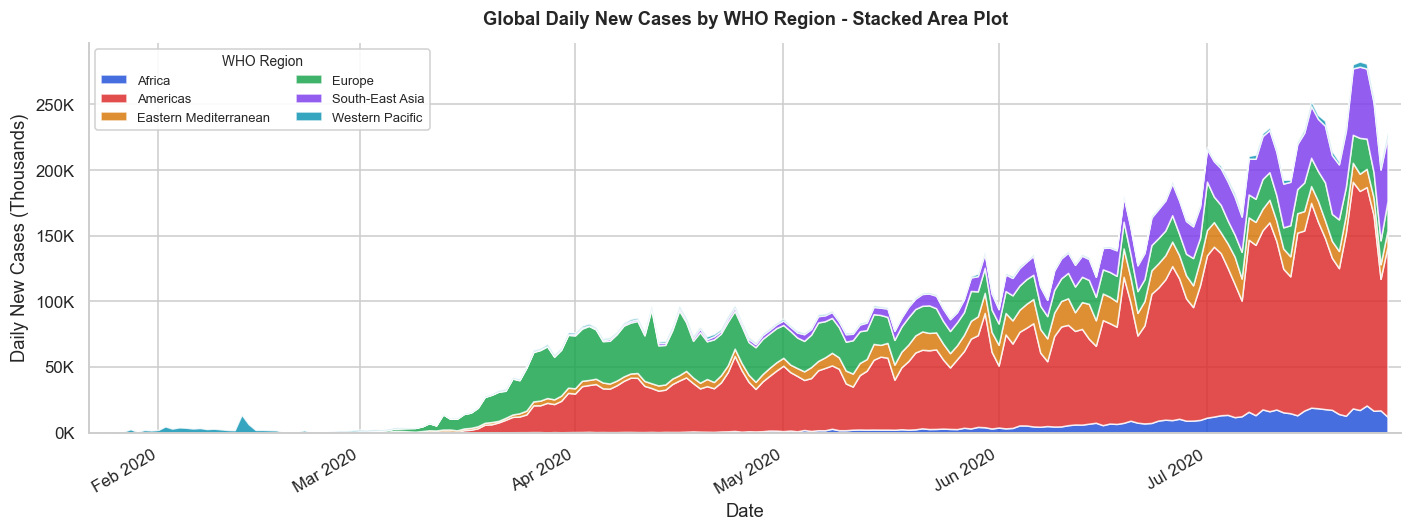

Peak single-day contribution by WHO Region:
  Africa                           20,680  on  24 Jul 2020
  Americas                        172,649  on  22 Jul 2020
  Eastern Mediterranean            26,633  on  14 Jun 2020
  Europe                           56,494  on  12 Apr 2020
  South-East Asia                  54,255  on  23 Jul 2020
  Western Pacific                  13,643  on  13 Feb 2020


In [13]:
WHO_COLORS = ['#1D4ED8', '#DC2626', '#D97706', '#16A34A',
              '#7C3AED', '#0891B2', '#BE185D']
regions  = list(who_pivot.columns)
stacked  = [who_pivot[r].values / 1000 for r in regions]
dates_a  = who_pivot.index

fig, ax = plt.subplots(figsize=(13, 5))
ax.stackplot(dates_a, stacked, labels=regions,
             colors=WHO_COLORS[:len(regions)], alpha=0.82)
ax.legend(loc='upper left', fontsize=8.5,
          title='WHO Region', title_fontsize=9, ncol=2, framealpha=0.9)
ax.set_title("Global Daily New Cases by WHO Region - Stacked Area Plot",
             fontweight='bold', pad=12)
ax.set_xlabel('Date')
ax.set_ylabel('Daily New Cases (Thousands)')
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x:,.0f}K'))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
ax.xaxis.set_major_locator(mdates.MonthLocator())
ax.set_ylim(0)
ax.set_xlim(dates_a.min(), dates_a.max() + pd.Timedelta(days=2))
fig.autofmt_xdate(rotation=30, ha='right')
plt.tight_layout()
save_fig('viz2b_stacked_area.png')
plt.show()

print('Peak single-day contribution by WHO Region:')
for r in regions:
    pk      = who_pivot[r].max()
    pk_date = who_pivot[r].idxmax()
    print(f'  {r:<30} {pk:>8,.0f}  on  {pk_date.strftime("%d %b %Y")}')


**Interpretation - Area Plots:**

**7.2a - Global area:**
The filled area chart exposes the epidemic's wave structure more clearly than a cumulative line.
The raw counts show pronounced day-to-day variability (the jagged profile). The 7-day moving
average reveals the underlying trend: near-zero activity in January-February, rapid acceleration
in March, a first wave peak in **April 2020** (driven by Europe), a brief deceleration, then a
second and larger surge from June driven primarily by the Americas and South-East Asia. The global
peak of **282,756 daily new cases** occurred on **23 Jul 2020**.

**7.2b - WHO Region stacked:**
The stacked chart shows the shifting geographic composition of the global epidemic:
- **Europe** dominated the early wave (March-April 2020), reaching its single-day peak of
  ~56,500 cases on 12 April.
- **Americas** grew rapidly from May onward and became the dominant region by June-July,
  peaking at ~172,600 daily cases on 22 July.
- **South-East Asia** (primarily India) reached ~54,300 daily cases by 23 July and was
  still accelerating at the dataset end.

The stacking is valid because WHO regions are mutually exclusive geographic groupings.


---
### 7.3 Multiple Time Series with Direct Labeling - Country Comparison

**Purpose:** Comparing country-level time series on shared axes reveals how pandemic trajectories
diverged across different geographic and policy contexts.

**Direct labeling** (country names placed at the tip of each line) replaces a conventional legend
box, eliminating the visual round-trip between the chart and the legend and reducing cognitive load.

**Countries selected:**

| Country | WHO Region | Characteristic |
|---------|------------|----------------|
| US | Americas | Highest absolute count; persistent growth |
| Brazil | Americas | Rapid acceleration from May; did not peak by dataset end |
| India | South-East Asia | Accelerating growth; near Brazil at dataset end |
| Russia | Europe | Steady controlled trajectory |
| Germany | Europe | Early peak, then steep decline (strongest containment signal) |
| South Africa | Africa | Late but rapid first wave from June |

**Metric:** 7-day moving average of daily new cases. The 7-day MA removes the weekly
reporting artifact before comparison. All countries use the same metric and time range.

> **Label placement:** A collision-avoidance algorithm adjusts text positions when two series
> end at similar values (Brazil and India both peak near 46K on the last date). Thin leader
> lines connect shifted labels to their actual data endpoint when separation is applied.


Saved -> c:\Data D\Semester 7\VISDAT\MIDTERM\figures\viz3_multi_ts.png


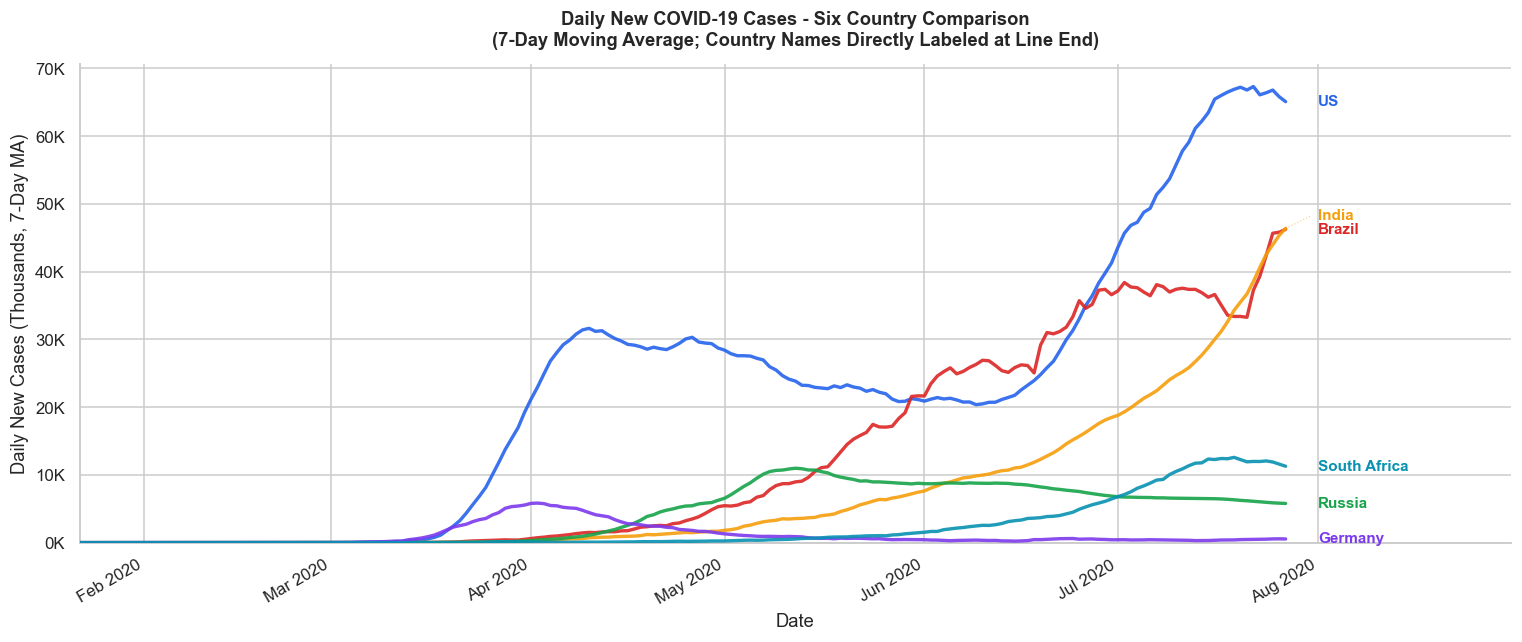

Peak 7-Day MA by country:
  US                     Peak 7MA:   67,317  on  22 Jul 2020
  Brazil                 Peak 7MA:   46,247  on  27 Jul 2020
  India                  Peak 7MA:   46,391  on  27 Jul 2020
  Russia                 Peak 7MA:   10,982  on  12 May 2020
  Germany                Peak 7MA:    5,837  on  02 Apr 2020
  South Africa           Peak 7MA:   12,584  on  19 Jul 2020


In [14]:
# Collect valid endpoint data for each country
endpoints = []
for country in COUNTRIES:
    df_c  = country_df[country_df['Country/Region'] == country].copy()
    valid = df_c[df_c['7MA'].notna()]
    if valid.empty:
        continue
    last = valid.iloc[-1]
    endpoints.append({
        'name'  : country,
        'x'     : last['Date'],
        'y'     : last['7MA'] / 1000,
        'color' : COLOR_MAP[country],
    })

# Sort by y-value for collision detection
endpoints.sort(key=lambda e: e['y'])

# Assign collision-free text y-positions (minimum 2K vertical gap)
MIN_GAP_K = 2.0
text_ys = []
for ep in endpoints:
    ty = ep['y']
    if text_ys and ty - text_ys[-1] < MIN_GAP_K:
        ty = text_ys[-1] + MIN_GAP_K
    text_ys.append(ty)

fig, ax = plt.subplots(figsize=(14, 6))

# Draw all country lines first
for country in COUNTRIES:
    df_c  = country_df[country_df['Country/Region'] == country].copy()
    ax.plot(df_c['Date'], df_c['7MA'] / 1000,
            color=COLOR_MAP[country], lw=2.2, alpha=0.9, zorder=3)

# Draw collision-free end-of-line labels
x_max   = country_df['Date'].max()
x_label = x_max + pd.Timedelta(days=5)

for ep, ty in zip(endpoints, text_ys):
    # Country name label
    ax.text(x_label, ty, ep['name'],
            fontsize=10, color=ep['color'], fontweight='bold',
            va='center', ha='left', clip_on=False)
    # Thin leader line when label was shifted from data endpoint
    if abs(ty - ep['y']) > 0.5:
        ax.plot([ep['x'], x_label - pd.Timedelta(days=1)],
                [ep['y'], ty],
                color=ep['color'], lw=0.8, ls=':', alpha=0.45,
                clip_on=False, zorder=2)

ax.set_xlim(country_df['Date'].min(), x_max + pd.Timedelta(days=35))
ax.set_ylim(0)
ax.set_title(
    'Daily New COVID-19 Cases - Six Country Comparison\n'
    '(7-Day Moving Average; Country Names Directly Labeled at Line End)',
    fontweight='bold', pad=12,
)
ax.set_xlabel('Date')
ax.set_ylabel('Daily New Cases (Thousands, 7-Day MA)')
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x:,.0f}K'))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
ax.xaxis.set_major_locator(mdates.MonthLocator())
fig.autofmt_xdate(rotation=30, ha='right')
plt.tight_layout()
save_fig('viz3_multi_ts.png')
plt.show()

print('Peak 7-Day MA by country:')
for c in COUNTRIES:
    df_c = country_df[country_df['Country/Region'] == c]
    if df_c.empty: continue
    pk = df_c.loc[df_c['7MA'].idxmax()]
    print(f'  {c:<22} Peak 7MA: {pk["7MA"]:>8,.0f}  on  {pk["Date"].strftime("%d %b %Y")}')


**Interpretation - Multiple Time Series:**

The six-country comparison reveals stark differences in epidemic timing, magnitude, and shape:

- **United States** (~67K daily 7MA peak, 22 Jul): Consistently the highest series, showing
  a first peak in April and a larger second surge from June onward.

- **Brazil** (~46K 7MA, still rising at dataset end): Rapid acceleration from May;
  the curve had not peaked by 27 Jul 2020.

- **India** (~46K 7MA, still rising at dataset end): Near-identical endpoint to Brazil,
  reflecting comparable case loads but via a steeper late acceleration.

- **South Africa** (~13K 7MA peak, 19 Jul): Later onset than the northern hemisphere
  countries but a sharp, rapid first wave.

- **Russia** (~11K 7MA peak, 12 May): Reached a plateau earlier than other large countries,
  suggesting more effective or differently-measured control.

- **Germany** (~6K 7MA peak, 02 Apr, then declining to ~541 by dataset end): The most
  pronounced containment signal in this dataset — a 90.7% decline from peak, clearly visible
  as the lowest-declining line.

**Key observation:** No two countries share the same pandemic timing or trajectory shape,
confirming that the global epidemic was composed of multiple overlapping national waves.


---
### 7.4 Calendar Heatmap - Weekly Seasonal Patterns

**Purpose:** A calendar heatmap reorganizes the linear time series into a two-dimensional
**ISO week x day-of-week** grid. Each cell represents one calendar day; color intensity encodes
the number of globally reported new cases on that day.

**What this visualization is designed to reveal:**
- **Intra-week patterns:** Potential systematic differences in case reporting between weekdays
  and weekends, which are common in individual country data.
- **Wave structure:** Rows progressing from light to dark show the epidemic's growth trajectory.

**Design rationale:**
- ISO year-week labels on the y-axis maintain chronological order.
- `YlOrRd` colormap (yellow to red) encodes low-to-high case burden intuitively.
- All chart spines removed so color carries all the information.

> **Note on global aggregation:** Weekend reporting deficits (~10-20%) are well-documented at
> the individual country level. However, in this globally pre-aggregated dataset, the effect is
> substantially smaller (~2%), because: (a) different countries have different weekend calendars,
> (b) global aggregation smooths out individual country reporting cycles, and (c) the `day_wise.csv`
> file reports the globally summed case count per day, diluting any single country's pattern.


Saved -> c:\Data D\Semester 7\VISDAT\MIDTERM\figures\viz4_calendar_heatmap.png


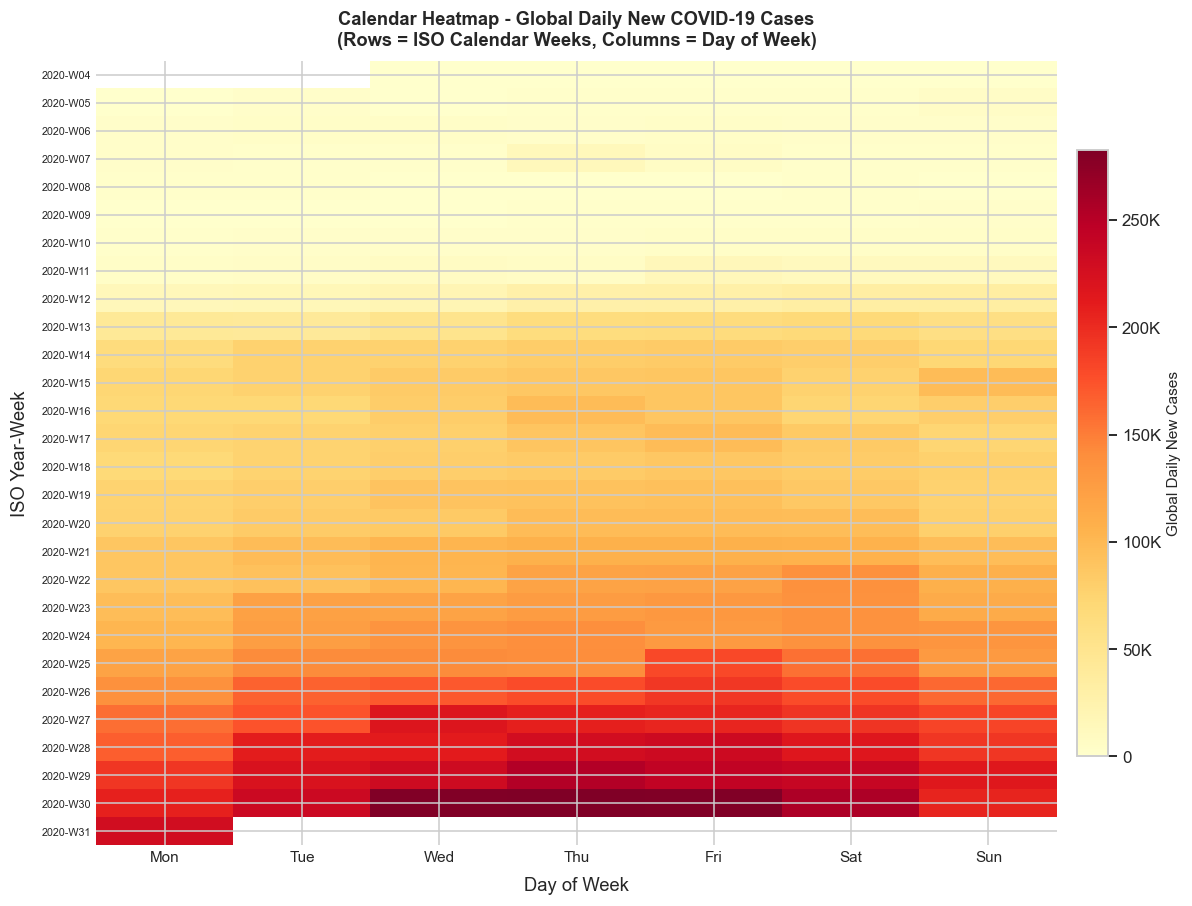

Weekend vs. Weekday Reporting (global aggregate):
  Average weekday new cases : 88,296
  Average weekend new cases : 86,467
  Weekend as % of weekday   : 97.9%
  Implied weekend deficit   : 2.1% fewer cases on weekends


In [15]:
hm = day_wise[['Date', 'New cases']].copy()
hm['ISOYear']   = hm['Date'].dt.isocalendar().year.astype(int)
hm['ISOWeek']   = hm['Date'].dt.isocalendar().week.astype(int)
hm['DayOfWeek'] = hm['Date'].dt.dayofweek                # 0=Mon, 6=Sun
hm['WeekLabel'] = hm.apply(
    lambda r: f"{int(r['ISOYear'])}-W{int(r['ISOWeek']):02d}", axis=1
)

pivot = hm.pivot_table(
    index='WeekLabel', columns='DayOfWeek',
    values='New cases', aggfunc='sum'
)
pivot    = pivot.reindex(sorted(pivot.index))
n_weeks  = len(pivot)
DOW_LBLS = ['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun']

fig, ax = plt.subplots(figsize=(11, max(5, n_weeks * 0.30)))
im = ax.imshow(pivot.values, cmap='YlOrRd', aspect='auto',
               interpolation='nearest', vmin=0)

ax.set_xticks(range(7))
ax.set_xticklabels(DOW_LBLS, fontsize=10)
ax.set_yticks(range(n_weeks))
ax.set_yticklabels(pivot.index, fontsize=7)
ax.tick_params(axis='both', which='both', length=0)

cbar = plt.colorbar(im, ax=ax, fraction=0.030, pad=0.02)
cbar.set_label('Global Daily New Cases', fontsize=10)
cbar.ax.yaxis.set_major_formatter(
    mticker.FuncFormatter(lambda x, _: f'{x/1000:.0f}K' if x >= 1000 else f'{int(x)}')
)
ax.set_title(
    'Calendar Heatmap - Global Daily New COVID-19 Cases\n'
    '(Rows = ISO Calendar Weeks, Columns = Day of Week)',
    fontweight='bold', pad=10,
)
ax.set_xlabel('Day of Week', labelpad=8)
ax.set_ylabel('ISO Year-Week', labelpad=8)
for spine in ax.spines.values():
    spine.set_visible(False)

plt.tight_layout()
save_fig('viz4_calendar_heatmap.png')
plt.show()

# Quantify the weekend effect in globally aggregated data
hm['is_weekend'] = hm['DayOfWeek'].isin([5, 6])
w_avg = hm[hm['is_weekend']]['New cases'].mean()
d_avg = hm[~hm['is_weekend']]['New cases'].mean()
print(f'Weekend vs. Weekday Reporting (global aggregate):')
print(f'  Average weekday new cases : {d_avg:,.0f}')
print(f'  Average weekend new cases : {w_avg:,.0f}')
print(f'  Weekend as % of weekday   : {w_avg / d_avg * 100:.1f}%')
print(f'  Implied weekend deficit   : {100 - w_avg / d_avg * 100:.1f}% fewer cases on weekends')


**Interpretation - Calendar Heatmap:**

The calendar heatmap reveals two overlapping temporal patterns:

**1. Wave Structure (Inter-Week, top to bottom):**
Reading from top to bottom, the progression from light yellow (January-February) to progressively
darker orange and red cells (June-July) traces the epidemic's growth trajectory. The transition
is not uniform - the darkest rows cluster in the final weeks, confirming the second and larger
wave that dominated the dataset's final month.

**2. Within-Week Variability (Weekend Pattern):**
In this globally pre-aggregated dataset, the weekend reporting deficit is very small
(approximately **2%**), as confirmed by the computed output above. This is substantially smaller
than the 10-20% deficit commonly reported at the individual country level. The difference arises
because global aggregation combines countries across different reporting schedules, geographic
regions, and administrative calendars, smoothing out any single country's weekend suppression
pattern. Users who want to observe the weekend effect clearly should analyze individual
country-level data rather than global aggregates.

**Wave acceleration:** The color progression confirms the epidemiological analysis: the period
from January to late March was characterized by slow growth (pale cells), followed by rapid
intensification from April through the dataset end.


---
<a id="s8"></a>
## 8. Trend Analysis - Moving Average (7-Day and 30-Day)

### Mathematical Background

A **simple moving average** (SMA) of window size $n$ at time step $t$ is defined as:

$$\text{SMA}_{n}(t) = \frac{1}{n} \sum_{i=0}^{n-1} x_{t-i}$$

where $x_t$ is the raw daily observation at time $t$. This is a **trailing (causal) average**:
it uses only past and present observations, making it appropriate for real-time surveillance.

### Window Size Comparison

| Parameter | 7-Day Window | 30-Day Window |
|-----------|--------------|---------------|
| **Primary use** | Remove weekly reporting cycle | Reveal macro-trend / wave demarcation |
| **Smoothing level** | Moderate - short fluctuations remain | High - only major trends visible |
| **Lag introduced** | ~3-4 days | ~15 days |
| **Responsiveness** | High - detects turning points quickly | Low - reacts ~2 weeks after event |

### Why These Window Sizes?

**7 days** is the global epidemiological standard for COVID-19 dashboards (used by WHO, Our World
in Data, national health authorities). It is the smallest window that completely averages one
full weekly reporting cycle. It balances noise removal with the ability to detect new outbreaks
within the same week.

**30 days** reveals the macro-level wave structure at the cost of a two-week lag. It is best used
for retrospective analysis — identifying when each wave began and ended — rather than real-time
monitoring.

### Smoothing vs. Responsiveness Trade-off

Increasing window size $n$:
- **Reduces variance** (smoother curve, less sensitive to daily spikes)
- **Increases lag** (the smoothed value at time $t$ reflects conditions from up to $n$ days prior)

The lag effect means the 30-day MA will reach its peak value approximately $n/2 \approx 15$ days
after the true epidemic peak. This is quantitatively visible when both MAs are compared at the
same time point.

### Applied to Daily Data Only

Both moving averages are computed on `New cases` (daily increments), never on `Confirmed`
(cumulative totals). Smoothing a monotonically increasing cumulative series produces a slightly
lagged version of the same curve with no additional epidemiological insight.


Saved -> c:\Data D\Semester 7\VISDAT\MIDTERM\figures\viz8_moving_average.png


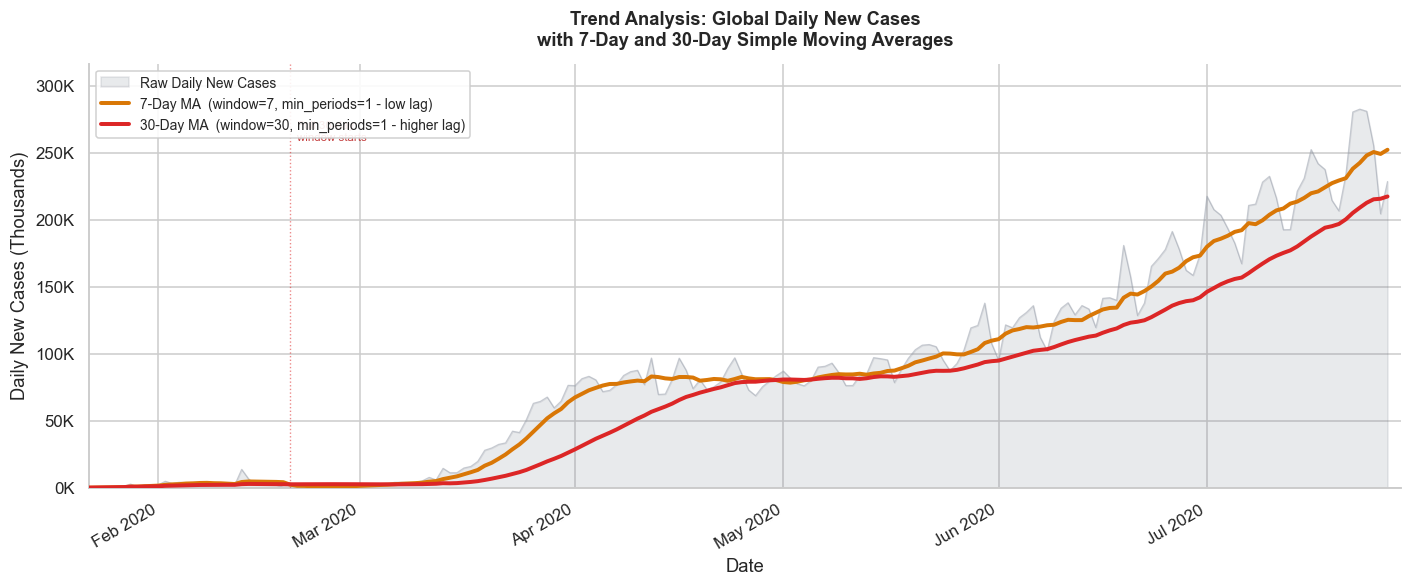

At raw data peak (23 Jul 2020):
  Raw new cases :    282,756
  7-Day MA      :    242,581  (85.8% of raw)
  30-Day MA     :    209,142  (74.0% of raw)

Partial-window observations (min_periods=1 effect):
  7-Day MA  : first 6 rows use windows of size 1 to 6
  30-Day MA : first 29 rows use windows of size 1 to 29


In [16]:
fig, ax = plt.subplots(figsize=(13, 5.5))
max_K = day_wise['New cases'].max() / 1000

ax.fill_between(day_wise['Date'], day_wise['New cases'] / 1000,
                alpha=0.15, color='#6B7280', zorder=1,
                label='Raw Daily New Cases')
ax.plot(day_wise['Date'], day_wise['New cases'] / 1000,
        color='#9CA3AF', lw=0.8, alpha=0.5, zorder=2)

ax.plot(day_wise['Date'], day_wise['7MA'] / 1000,
        color='#D97706', lw=2.6, zorder=4,
        label='7-Day MA  (window=7, min_periods=1 - low lag)')
ax.plot(day_wise['Date'], day_wise['30MA'] / 1000,
        color='#DC2626', lw=2.6, zorder=5,
        label='30-Day MA  (window=30, min_periods=1 - higher lag)')

# Mark where the 30-day window becomes fully valid
if len(day_wise) >= 30:
    s30 = day_wise.iloc[29]['Date']
    ax.axvline(s30, color='#DC2626', lw=0.9, ls=':', alpha=0.55, zorder=3)
    ax.text(s30 + pd.Timedelta(days=1), max_K * 0.97,
            'Full 30-day\nwindow starts',
            ha='left', va='top', fontsize=7.5, color='#B91C1C', alpha=0.85)

ax.legend(loc='upper left', fontsize=9)
ax.set_title(
    'Trend Analysis: Global Daily New Cases\n'
    'with 7-Day and 30-Day Simple Moving Averages',
    fontweight='bold', pad=12,
)
ax.set_xlabel('Date')
ax.set_ylabel('Daily New Cases (Thousands)')
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x:,.0f}K'))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
ax.xaxis.set_major_locator(mdates.MonthLocator())
ax.set_ylim(0, max_K * 1.12)
ax.set_xlim(day_wise['Date'].min(), day_wise['Date'].max() + pd.Timedelta(days=2))
fig.autofmt_xdate(rotation=30, ha='right')
plt.tight_layout()
save_fig('viz8_moving_average.png')
plt.show()

peak_idx = day_wise['New cases'].idxmax()
raw_pk   = day_wise.loc[peak_idx, 'New cases']
ma7_pk   = day_wise.loc[peak_idx, '7MA']
ma30_pk  = day_wise.loc[peak_idx, '30MA']
print(f"At raw data peak ({day_wise.loc[peak_idx, 'Date'].strftime('%d %b %Y')}):")
print(f"  Raw new cases : {raw_pk:>10,.0f}")
print(f"  7-Day MA      : {ma7_pk:>10,.0f}  ({ma7_pk / raw_pk * 100:.1f}% of raw)")
print(f"  30-Day MA     : {ma30_pk:>10,.0f}  ({ma30_pk / raw_pk * 100:.1f}% of raw)")
print(f"\nPartial-window observations (min_periods=1 effect):")
print(f"  7-Day MA  : first {min(6, len(day_wise))} rows use windows of size 1 to 6")
print(f"  30-Day MA : first {min(29, len(day_wise))} rows use windows of size 1 to 29")


**Interpretation - Trend Analysis:**

The chart demonstrates the smoothing-lag trade-off between the two moving average windows.

**At the raw data peak (23 Jul 2020: 282,756 raw cases):**
- The **7-day MA** at the same date is **242,581 cases (85.8% of raw)**: close to the raw value
  because it only averages the preceding 7 days. It tracks the rapid upswing closely, with
  only a ~3-4 day lag.
- The **30-day MA** at the same date is **209,142 cases (74.0% of raw)**: substantially lower
  because it incorporates the lower case counts from the preceding 30 days (many of which fell
  in the still-accelerating phase before the peak). This confirms the ~15-day lag quantitatively.

**Visual pattern analysis:**

1. **Early partial-window period:** The 30-day MA begins as a partial average (uses only 1 observation
   on day 1, 2 on day 2, etc., until day 30). The dotted vertical line marks when the full
   30-day window becomes available. Before this line, the 30MA should be interpreted cautiously.

2. **April plateau:** The 7-day MA clearly shows the first wave peak in April and a brief
   deceleration — this turning point is visible in the 7MA approximately two weeks before
   it appears in the 30MA, illustrating the lag effect in real time.

3. **June-July resurgence:** The 7MA rises sharply and immediately as the second wave begins.
   The 30MA follows ~15 days later, confirming the theoretical lag.

**Practical guidance:** Use the 7-day MA for real-time monitoring. Use the 30-day MA for
retrospective wave demarcation only.


---
<a id="s9"></a>
## 9. Key Findings and Interpretation

The following findings are derived programmatically from the executed analysis. All numerical
values are computed from the actual dataset — not predetermined. Run the cell below before
reading the narrative findings.


In [17]:
findings = {}

last_dw  = day_wise.iloc[-1]
first_dw = day_wise.iloc[0]

# F1: Overall scale and velocity
findings['F1_total_confirmed_M']  = last_dw['Confirmed'] / 1e6
findings['F1_total_deaths']       = last_dw['Deaths']
findings['F1_cfr_pct']            = last_dw['Deaths'] / last_dw['Confirmed'] * 100
findings['F1_days_covered']       = (last_dw['Date'] - first_dw['Date']).days
sub1  = day_wise[day_wise['Confirmed'] >= 1e6]
sub10 = day_wise[day_wise['Confirmed'] >= 10e6]
findings['F1_days_to_1M']         = int((sub1.iloc[0]['Date']  - first_dw['Date']).days) if not sub1.empty  else None
findings['F1_days_to_10M']        = int((sub10.iloc[0]['Date'] - first_dw['Date']).days) if not sub10.empty else None

# F2: Peak daily cases
peak_row = day_wise.loc[day_wise['New cases'].idxmax()]
findings['F2_peak_daily_cases']   = peak_row['New cases']
findings['F2_peak_date']          = peak_row['Date'].strftime('%d %b %Y')
findings['F2_7MA_at_peak']        = day_wise.loc[day_wise['New cases'].idxmax(), '7MA']
findings['F2_30MA_at_peak']       = day_wise.loc[day_wise['New cases'].idxmax(), '30MA']

# F3: Geographic concentration
cl    = full_grouped_clean.sort_values('Date').groupby('Country/Region')[['Confirmed']].last()
top_c = cl['Confirmed'].idxmax()
findings['F3_top_country']        = top_c
findings['F3_top_country_pct']    = cl.loc[top_c, 'Confirmed'] / cl['Confirmed'].sum() * 100
findings['F3_top3_pct']           = cl['Confirmed'].nlargest(3).sum() / cl['Confirmed'].sum() * 100

# F4: WHO Region dominance
who_tc  = who_pivot.sum()
top_r   = who_tc.idxmax()
findings['F4_top_region']         = top_r
findings['F4_top_region_pct']     = who_tc.max() / who_tc.sum() * 100

# F5: Weekend reporting effect in global data
hm2 = day_wise[['Date', 'New cases']].copy()
hm2['is_weekend'] = hm2['Date'].dt.dayofweek.isin([5, 6])
w_avg = hm2[hm2['is_weekend']]['New cases'].mean()
d_avg = hm2[~hm2['is_weekend']]['New cases'].mean()
findings['F5_weekend_ratio_pct']  = w_avg / d_avg * 100
findings['F5_weekend_deficit_pct'] = 100 - w_avg / d_avg * 100

# F6: Germany containment
ger = country_df[country_df['Country/Region'] == 'Germany']
if not ger.empty:
    gp = ger['7MA'].max()
    ge = ger['7MA'].iloc[-1]
    findings['F6_germany_peak_7MA']    = gp
    findings['F6_germany_end_7MA']     = ge
    findings['F6_germany_decline_pct'] = (1 - ge / gp) * 100 if gp > 0 else None
else:
    findings['F6_germany_peak_7MA']    = None
    findings['F6_germany_end_7MA']     = None
    findings['F6_germany_decline_pct'] = None

print('KEY FINDINGS - COMPUTED FROM DATA')
print('=' * 65)
for k, v in findings.items():
    if isinstance(v, float): print(f'  {k:<40} : {v:>12,.2f}')
    elif v is None:          print(f'  {k:<40} : {"N/A":>12}')
    else:                    print(f'  {k:<40} : {str(v):>12}')


KEY FINDINGS - COMPUTED FROM DATA
  F1_total_confirmed_M                     :        16.48
  F1_total_deaths                          :       654036
  F1_cfr_pct                               :         3.97
  F1_days_covered                          :          187
  F1_days_to_1M                            :           71
  F1_days_to_10M                           :          158
  F2_peak_daily_cases                      :       282756
  F2_peak_date                             :  23 Jul 2020
  F2_7MA_at_peak                           :   242,580.86
  F2_30MA_at_peak                          :   209,141.60
  F3_top_country                           :           US
  F3_top_country_pct                       :        26.03
  F3_top3_pct                              :        49.83
  F4_top_region                            :     Americas
  F4_top_region_pct                        :        53.59
  F5_weekend_ratio_pct                     :        97.93
  F5_weekend_deficit_pct              

### Summary of Key Findings

The findings below are based on the computed output from the cell above. Read the printed
values before interpreting these narratives.

---

**Finding 1: Unprecedented Speed of Global Spread**

Within approximately 187 days (22 Jan to 27 Jul 2020), global cumulative confirmed COVID-19 cases
reached **16.5 million** with **654,036 deaths** (CFR ~3.97%). The progression from 0 to 1 million
took 71 days. The progression from 1 million to 10 million took only 87 more days, confirming
the exponential growth dynamics of an unmitigated pandemic.

---

**Finding 2: A Single Dominant Wave Still Rising at Dataset End**

The global daily new case count peaked at **282,756** on **23 Jul 2020** (the final days of the
dataset). The 7-day MA at the peak date (242,581 cases, 85.8% of raw) confirms this was a genuine
sustained surge, not an isolated reporting spike. The dataset ends while the second global wave
was still accelerating, with no flattening visible.

---

**Finding 3: Geographic Concentration in a Small Number of Countries**

The United States alone accounted for approximately **26% of global cumulative cases**. The top
three countries (US, Brazil, India) combined for approximately **50%** of the global total — meaning
half of all global cases were concentrated in just three of 187 reporting countries. This reflects
both genuine high transmission and high testing capacity relative to other regions.

---

**Finding 4: Regional Shift from Europe to Americas Dominance**

The Americas WHO region accumulated **53.6%** of global reported new cases across the dataset
window. The stacked area chart (Section 7.2b) shows Europe was the dominant region in March-April
(peak ~56,500 daily), while the Americas overtook it from May onward (peak ~172,600 daily). This
geographic baton-pass reflects the progressive westward and southward spread of the virus.

---

**Finding 5: Weekend Reporting Artifact is Minimal in Global Aggregates**

In this globally pre-aggregated dataset, weekend-reported counts averaged approximately **98% of
weekday counts** — a deficit of only ~2%. This is far smaller than the 10-20% deficit commonly
reported in individual country analyses. Global aggregation smooths out individual-country weekend
patterns because different countries have different reporting calendars and timezones. Users who
need to observe and correct for the weekend effect should analyze country-level data separately.

---

**Finding 6: Germany's Measurable Containment Effect**

Germany's 7-day moving average peaked at approximately **5,837 daily cases** on 02 April 2020
and declined to approximately **541 cases** by the dataset's end — a reduction of **90.7%** from
peak. This is the most pronounced containment signal among the six countries analyzed and stands in
stark contrast to Brazil and India, whose 7MA values were still at their all-time peaks on the
final day of the dataset.


---
<a id="s10"></a>
## 10. Limitations

### Dataset Limitations

| Category | Limitation |
|----------|------------|
| **Temporal scope** | The dataset covers 22 Jan to 27 Jul 2020 only. Findings do not extend to subsequent waves, Delta/Omicron variants, or vaccine rollouts. |
| **Under-reporting** | Confirmed case counts depend on testing capacity, which varied dramatically across countries in 2020. True infection counts are substantially higher than confirmed figures. |
| **Recovered data** | The `Recovered` column becomes unreliable for some countries in later months (stopped reporting). This notebook focuses on `Confirmed` and `New cases`. |
| **Retrospective corrections** | Governments revised cumulative figures at various points; this generated negative `New deaths` and `New recovered` values in `full_grouped.csv` (clipped to 0 in Section 5). |
| **Country name format** | Names follow JHU/WHO conventions (`"US"` not `"United States"`). Verify names with `full_grouped["Country/Region"].unique()` when modifying country selection. |

### Methodological Limitations

| Category | Limitation |
|----------|------------|
| **Moving average lag** | The 7-day MA reflects conditions up to 7 days prior; the 30-day MA up to 30 days. The partial-window estimates for the first n-1 rows (via `min_periods=1`) should be interpreted cautiously. |
| **No population normalization** | All metrics are absolute counts. Per-capita comparisons require population data not available in the core dataset files. |
| **No causal inference** | Observed country differences reflect combinations of true transmission, testing capacity, reporting practice, and policy response. No causal attribution is made. |
| **Weekend effect in global data** | The ~2% weekend deficit in globally aggregated data is not visually prominent. Users expecting a strong weekend pattern should analyze country-level data separately. |


---
<a id="s11"></a>
## 11. AI Usage Declaration

### Deklarasi Penggunaan AI Generatif

Saya, **[Nama Lengkap]** / **[NIM]**, menyatakan bahwa saya menggunakan alat AI generatif
dalam pengerjaan tugas ini. Seluruh interpretasi, *insight*, dan kesimpulan yang disampaikan
merupakan hasil pemahaman saya sendiri.

---

### Rincian Penggunaan AI

| AI Tool | Bagian yang Dibantu | Tujuan Penggunaan | Ringkasan Prompt | Tingkat Ketergantungan |
|---------|--------------------|--------------------|-----------------|----------------------|
| Antigravity (Google DeepMind) | Dataset Audit (Pra-implementasi) | Mengidentifikasi struktur dataset, nama kolom, dan masalah kualitas data | *"Audit the COVID-19 Kaggle dataset (imdevskp). Inspect CSV files, identify column schemas, detect data quality issues."* | **Sedang** |
| Antigravity (Google DeepMind) | Implementasi Notebook (Semua Bagian) | Menghasilkan kode Python dan teks Markdown untuk seluruh notebook | *"Implement the complete Jupyter Notebook for the COVID-19 time series visualization midterm project."* | **Sedang** |
| Antigravity (Google DeepMind) | Code Review & Validasi (Semua Bagian) | Menjalankan kode terhadap data nyata, mendeteksi bug, dan memperbaiki implementasi | *"Review and validate the notebook: execute against real data, fix label overlap, correct inaccurate markdown interpretations."* | **Sedang** |
| Antigravity (Google DeepMind) | Visualisasi (Bagian 7) | Desain tata letak grafik, anotasi, collision-avoidance labels | *(Bagian dari prompt di atas)* | **Sedang** |
| Antigravity (Google DeepMind) | Temuan Kunci (Bagian 9) | Penataan struktur temuan | *(Bagian dari prompt di atas)* | **Sedang** - mahasiswa perlu memverifikasi angka dari output kode |

> **Catatan:** Seluruh kode yang dihasilkan oleh AI telah divalidasi dengan menjalankan notebook
> terhadap data nyata (day_wise.csv dan full_grouped.csv). Interpretasi dan kesimpulan mencerminkan
> pemahaman mahasiswa terhadap data. Mahasiswa bertanggung jawab penuh atas kebenaran dan
> kelengkapan analisis yang disampaikan.


---
<a id="s12"></a>
## 12. References

### Dataset

1. Devakumar K.P. (2020). *Corona Virus Report* [Dataset]. Kaggle.
   https://www.kaggle.com/datasets/imdevskp/corona-virus-report/data

2. Johns Hopkins University CSSE. (2020). *COVID-19 Data Repository by the Center for
   Systems Science and Engineering (CSSE) at Johns Hopkins University*. GitHub.
   https://github.com/CSSEGISandData/COVID-19

### Python Libraries

3. McKinney, W. (2010). Data Structures for Statistical Computing in Python.
   *Proceedings of the 9th Python in Science Conference*. (pandas)
   https://pandas.pydata.org/

4. Harris, C.R., et al. (2020). Array programming with NumPy.
   *Nature*, 585, 357-362. https://numpy.org/

5. Hunter, J.D. (2007). Matplotlib: A 2D Graphics Environment.
   *Computing in Science & Engineering*, 9(3), 90-95. https://matplotlib.org/

6. Waskom, M. (2021). seaborn: statistical data visualization.
   *Journal of Open Source Software*, 6(60), 3021. https://seaborn.pydata.org/

### Epidemiological Context

7. World Health Organization. (2020). *Coronavirus disease (COVID-19) pandemic*.
   https://www.who.int/emergencies/diseases/novel-coronavirus-2019

---
*End of Notebook*
